# Health Costs Regression

A reproducible regression workflow for the public FreeCodeCamp health-costs teaching dataset. The target is `expenses`. Exact duplicate rows are reported and retained; grouped splits keep copies together.

The project evaluates Keras and compares mean and linear baselines with gradient boosting using five-fold grouped cross-validation on development data. It tests a log-transformed target and the smoker×BMI interaction. The final Keras model uses a separate validation set and an untouched grouped holdout. This is educational work, not a real pricing tool.

Setup: install the pinned dependencies and project package as described in `README.md` before running the notebook.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from health_costs.config import TARGET
from health_costs.data import load_dataset
from health_costs.model import load_artifacts, predict_expenses
from health_costs.training import train_project

%matplotlib inline

## Load and inspect the source data

The loader prefers an explicit local path, then `.cache/insurance.csv`, and otherwise makes one timed download. Exact duplicates are counted rather than silently removed.

In [2]:
dataset = load_dataset()
print(f'{len(dataset):,} rows × {dataset.shape[1]} columns')
print(f'Exact duplicate rows retained: {dataset.duplicated().sum()}')
display(dataset.describe(include='all').T)
print('Observed numeric ranges:')
display(dataset[['age', 'bmi', 'children', 'expenses']].agg(['min', 'max']).T)

1,338 rows × 7 columns
Exact duplicate rows retained: 1


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,1338.0,NaN,NaN,NaN,39.207025,14.04996,18.0,27.0,39.0,51.0,64.0
bmi,1338.0,NaN,NaN,NaN,30.665471,6.098382,16.0,26.3,30.4,34.7,53.1
children,1338.0,NaN,NaN,NaN,1.094918,1.205493,0.0,0.0,1.0,2.0,5.0
sex,1338,2,male,676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
smoker,1338,2,no,1064,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,1338,4,southeast,364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
expenses,1338.0,NaN,NaN,NaN,13270.422414,12110.01124,1121.87,4740.2875,9382.03,16639.915,63770.43


Observed numeric ranges:


,min,max
age,18.00,64.00
bmi,16.00,53.10
children,0.00,5.00
expenses,1121.87,63770.43


## Cross-validation and final training

The 20% holdout is removed before grouped cross-validation for both the Keras model and reference models. All preprocessors are fitted within each fold or on the final training subset only. The Keras model receives dense transformed features; `test_dataset` is already transformed for the original FCC grader.

In [3]:
run = train_project(dataset, run_cv=True, max_epochs=300)
model = run.model
train_dataset = run.train_dataset
train_labels = run.train_labels
test_dataset = run.test_dataset
test_labels = run.test_labels

display(run.cv_results)
print(f'Trained for {len(run.history.history["loss"])} epochs with early stopping.')
print(f'Final holdout rows: {len(test_labels)}')

,model,folds,mae_mean,mae_std,rmse_mean,r2_mean
0,gradient_boosting_log_target,5,2254.630094,246.655170,4777.829282,0.845814
1,keras_neural_network,5,2361.901404,342.316847,5446.239591,0.799801
2,gradient_boosting_with_interaction,5,2509.122005,571.026358,5718.556738,0.779301
3,linear_with_interaction,5,2908.104886,241.902744,4863.651497,0.840138
4,gradient_boosting_without_interaction,5,3834.843034,930.207965,7982.613049,0.566489
5,mean_baseline,5,9179.918428,404.859498,12207.468169,-0.005686


Trained for 114 epochs with early stopping.
Final holdout rows: 268


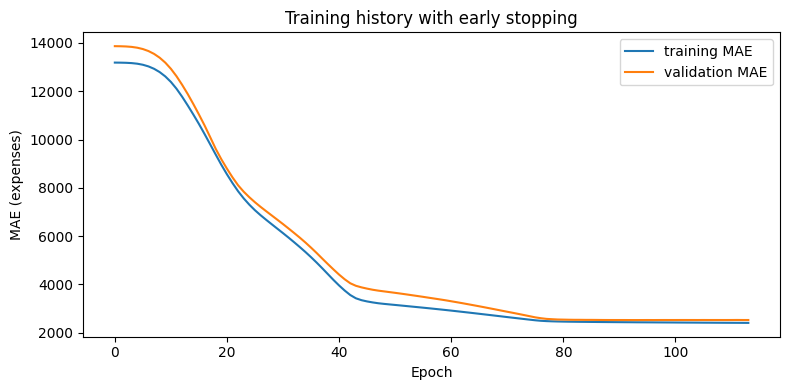

In [4]:
plt.figure(figsize=(8, 4))
plt.plot(run.history.history['loss'], label='training MAE')
plt.plot(run.history.history['val_loss'], label='validation MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE (expenses)')
plt.title('Training history with early stopping')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
import keras


model.compile(
    optimizer="adam",
    loss="mae",
    metrics=[
        keras.metrics.MeanAbsoluteError(name="mae"),
        keras.metrics.MeanSquaredError(name="mse"),
    ],
)

results = model.evaluate(
    test_dataset,
    test_labels.to_numpy(dtype="float32").reshape(-1, 1),
    verbose=2,
)

print("Evaluation results:", results)

9/9 - 0s - 11ms/step - loss: 2690.3179 - mae: 2689.8540 - mse: 34926472.0000
Evaluation results: [2690.31787109375, 2689.85400390625, 34926472.0]


9/9 - 0s - 2ms/step - loss: 2690.3179 - mae: 2689.8540 - mse: 34926472.0000
Testing set Mean Abs Error: 2689.85 expenses
You passed the challenge. Great job!
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


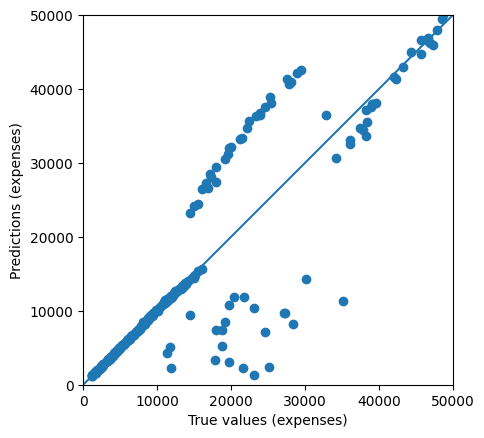

In [ ]:

loss, mae, mse = model.evaluate(test_dataset, test_labels, verbose=2)

print("Testing set Mean Abs Error: {:5.2f} expenses".format(mae))

if mae < 3500:
  print("You passed the challenge. Great job!")
else:
  print("The Mean Abs Error must be less than 3500. Keep trying.")

# Plot predictions.
test_predictions = model.predict(test_dataset).flatten()

a = plt.axes(aspect='equal')
plt.scatter(test_labels, test_predictions)
plt.xlabel('True values (expenses)')
plt.ylabel('Predictions (expenses)')
lims = [0, 50000]
plt.xlim(lims)
plt.ylim(lims)
_ = plt.plot(lims,lims)

## Reload and prediction check

The saved artifact is a bundle: Keras `.keras` model plus its fitted scikit-learn preprocessor and metadata. Inference accepts the original feature columns and warns when age, BMI, or children are outside the observed teaching-data ranges.

In [7]:
raw_test = dataset.drop(columns=TARGET).iloc[run.heldout_indices].reset_index(drop=True)
reloaded_model, reloaded_preprocessor, artifact_metadata = load_artifacts()
reloaded_predictions = predict_expenses(raw_test.iloc[:8], reloaded_model, reloaded_preprocessor)
np.testing.assert_allclose(reloaded_predictions, test_predictions[:8], rtol=1e-5, atol=1e-3)
print('Saved model reload reproduces predictions.')
print(artifact_metadata['warning'])

Saved model reload reproduces predictions.
Educational prediction on a small public teaching dataset; not real pricing.


## Limitations

Expenses are strongly right-skewed, and smoking status is strongly associated with the target in this dataset. Cross-validation reports the fold-to-fold MAE spread; the final holdout score is still one sample estimate. The interaction and log-target comparison are predictive experiments, not causal findings. This public dataset is small and intended for teaching; do not use its predictions for actual insurance pricing or individual financial decisions. See `DATASET_ATTRIBUTION.md` for source and licensing notes.